In [1]:
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm

In [2]:
df_notas = pd.read_csv('Base_Notas_v3.csv', index_col='id')
df_notas.head()

,horas_estudo,aulas_participadas,sono_medio,nota_exame
id,,,,
0,5.993428,8,7.343618,76.119754
1,4.723471,11,5.236960,60.929961
2,6.295377,12,7.324084,81.731317
3,8.046060,7,6.614918,82.699637
4,4.531693,5,6.323078,70.662399


In [3]:
df_notas.info()

<class 'pandas.core.frame.DataFrame'>
Index: 30 entries, 0 to 29
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   horas_estudo        30 non-null     float64
 1   aulas_participadas  30 non-null     int64  
 2   sono_medio          30 non-null     float64
 3   nota_exame          30 non-null     float64
dtypes: float64(3), int64(1)
memory usage: 1.2 KB


In [4]:
df_notas.describe().round(2)

,horas_estudo,aulas_participadas,sono_medio,nota_exame
count,30.00,30.00,30.00,30.00
mean,4.62,9.80,7.06,71.81
std,1.80,2.87,0.97,8.88
min,1.17,5.00,4.38,54.48
25%,3.82,8.00,6.54,66.41
50%,4.53,10.00,7.21,71.40
75%,5.72,12.00,7.82,78.10
max,8.16,14.00,8.56,89.47


In [5]:
df_notas.isna().sum()

,0
horas_estudo,0
aulas_participadas,0
sono_medio,0
nota_exame,0


<Axes: xlabel='horas_estudo', ylabel='nota_exame'>

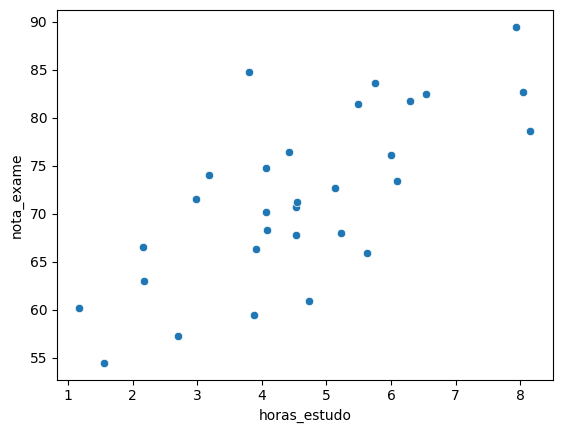

In [6]:
sns.scatterplot(df_notas, x='horas_estudo', y='nota_exame')

<Axes: xlabel='aulas_participadas', ylabel='nota_exame'>

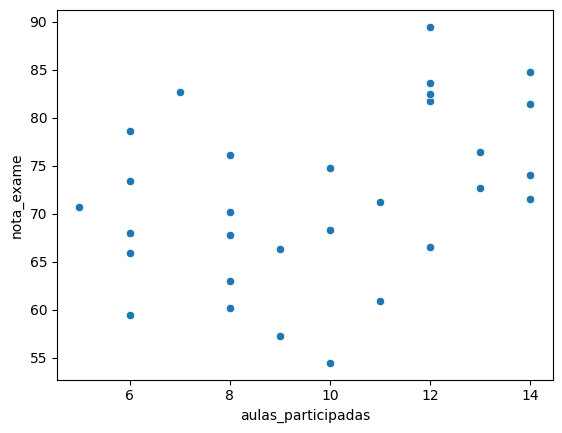

In [7]:
sns.scatterplot(df_notas, x='aulas_participadas', y='nota_exame')

<Axes: xlabel='sono_medio', ylabel='nota_exame'>

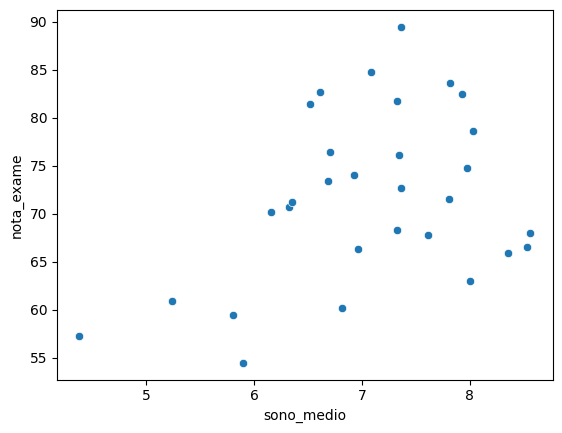

In [8]:
sns.scatterplot(df_notas, x='sono_medio', y='nota_exame')

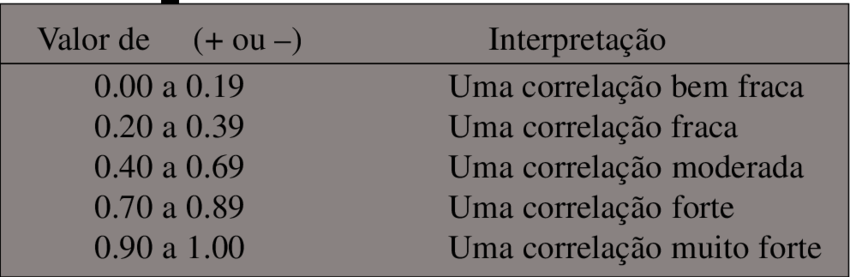

In [9]:
df_notas.corr()

,horas_estudo,aulas_participadas,sono_medio,nota_exame
horas_estudo,1.000000,-0.136144,0.215949,0.721178
aulas_participadas,-0.136144,1.000000,0.037439,0.385559
sono_medio,0.215949,0.037439,1.000000,0.370024
nota_exame,0.721178,0.385559,0.370024,1.000000


<Axes: >

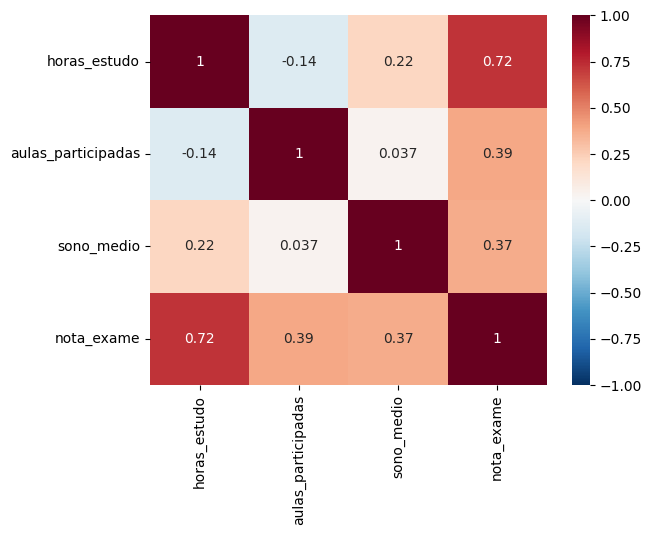

In [10]:
sns.heatmap(
    df_notas.corr(),
    cmap='RdBu_r',
    vmin=-1,vmax=1,
    annot=True
)

In [11]:
# alvo, dependente ou target
y = df_notas['nota_exame']

# intercepto
df_notas['intercepto'] = 1
x = df_notas[['intercepto','horas_estudo','aulas_participadas', 'sono_medio']]

In [12]:
#ajuste do modelo
modelo = sm.OLS(y,x)
resultado = modelo.fit()

In [13]:
print(resultado.summary())

                            OLS Regression Results                            
Dep. Variable:             nota_exame   R-squared:                       0.793
Model:                            OLS   Adj. R-squared:                  0.769
Method:                 Least Squares   F-statistic:                     33.24
Date:                Tue, 10 Mar 2026   Prob (F-statistic):           4.76e-09
Time:                        22:36:36   Log-Likelihood:                -83.926
No. Observations:                  30   AIC:                             175.9
Df Residuals:                      26   BIC:                             181.5
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
intercepto            27.9742      6